# Exploratory analysis: figures for the case study

Five charts built from the processed data. Each chart is saved to `reports/figures/`.
Run the cells from top to bottom. Chart 1 scans the full 59-million-row sales table once, so allow a few minutes.

In [2]:
import sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import config
from run_sql import statements, body_of

FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# DuckDB with the same views as the SQL files
con = duckdb.connect()
for chunk in statements((ROOT / "sql" / "01_views.sql").read_text()):
    body = body_of(chunk)
    if body:
        con.execute(body)

cls = pd.read_parquet(config.PROCESSED_DIR / "item_classes.parquet")
print(f"Series: {len(cls):,}")

Series: 30,490


## Chart 1: Revenue growth follows the number of products on sale

Question: is the rise in total revenue per day a rise in demand, or more products being sold?
Both lines are indexed to the first full month (February 2011 = 100). Partial months are dropped.
What to look for: the revenue line should rise with the products-on-sale line and stay at or below it.

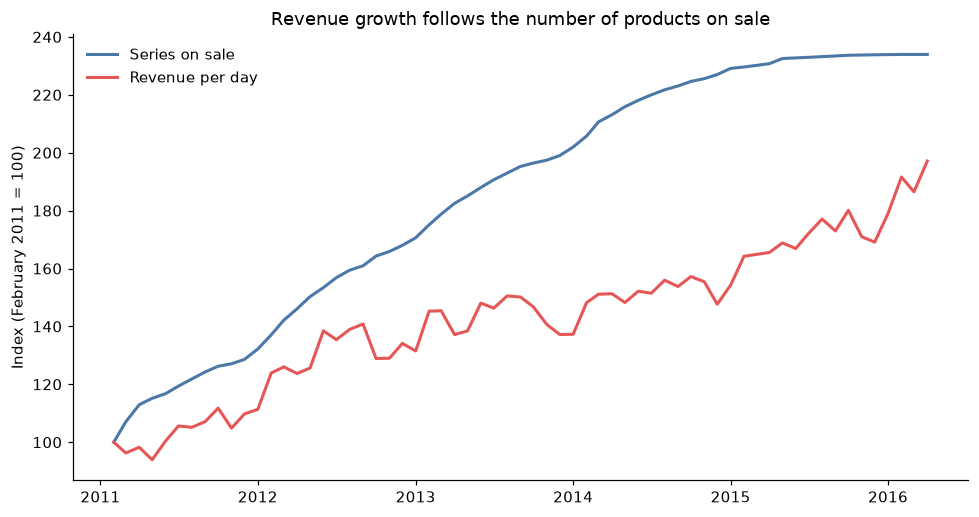

April 2016: series on sale index 234, revenue per day index 197


In [3]:
monthly = con.execute("""
    SELECT CAST(EXTRACT(year FROM sale_date) AS INTEGER) AS yr,
           CAST(EXTRACT(month FROM sale_date) AS INTEGER) AS mth,
           COUNT(DISTINCT d_num) AS days,
           SUM(revenue) AS revenue
    FROM sales_priced
    GROUP BY 1, 2
""").fetchdf()

on_sale = con.execute("""
    WITH m AS (
        SELECT "year" AS yr, "month" AS mth, MAX(d_num) AS last_day
        FROM calendar
        WHERE d_num <= 1941
        GROUP BY 1, 2
    )
    SELECT m.yr, m.mth, COUNT(*) AS series_on_sale
    FROM m
    JOIN availability a ON a.first_price_day <= m.last_day
    GROUP BY m.yr, m.mth
""").fetchdf()

df = monthly.merge(on_sale, on=["yr", "mth"]).sort_values(["yr", "mth"])
df = df[df["days"] >= 28].copy()                      # keep full months only
df["rev_per_day"] = df["revenue"] / df["days"]
df["date"] = pd.to_datetime(dict(year=df["yr"], month=df["mth"], day=1))

base = df.iloc[0]
df["revenue_index"] = df["rev_per_day"] / base["rev_per_day"] * 100
df["series_index"] = df["series_on_sale"] / base["series_on_sale"] * 100

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(df["date"], df["series_index"], label="Series on sale", color="#4c78a8", lw=2)
ax.plot(df["date"], df["revenue_index"], label="Revenue per day", color="#e45756", lw=2)
ax.set_ylabel(f"Index ({base['date']:%B %Y} = 100)")
ax.set_title("Revenue growth follows the number of products on sale")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / "fig_assortment_growth.png")
plt.show()

last = df.iloc[-1]
print(f"{last['date']:%B %Y}: series on sale index {last['series_index']:.0f}, revenue per day index {last['revenue_index']:.0f}")

## Chart 2: How often is a product on sale but not bought?

Question: the average zero share is about 60%. How much do products differ?
Each bar counts item-store series. Only days on or after the product's first price are used.
What to look for: a wide spread, from products that sell almost daily to products that rarely sell.

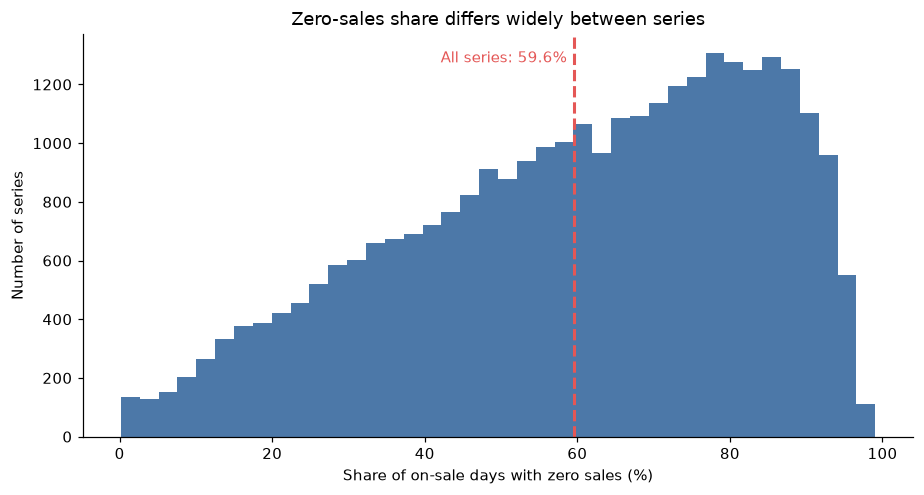

count    30490.000
mean         0.601
std          0.234
min          0.002
10%          0.259
50%          0.634
90%          0.885
max          0.991
Name: zero_share, dtype: float64


In [4]:
cls["zero_share"] = 1 - cls["sale_days"] / cls["avail_days"]
overall = (cls["avail_days"].sum() - cls["sale_days"].sum()) / cls["avail_days"].sum() * 100

fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.hist(cls["zero_share"] * 100, bins=40, color="#4c78a8")
ax.axvline(overall, color="#e45756", ls="--", lw=2)
ax.text(overall - 1, ax.get_ylim()[1] * 0.93, f"All series: {overall:.1f}%", color="#e45756", ha="right")
ax.set_xlabel("Share of on-sale days with zero sales (%)")
ax.set_ylabel("Number of series")
ax.set_title("Zero-sales share differs widely between series")
fig.tight_layout()
fig.savefig(FIG / "fig_zero_share_spread.png")
plt.show()

print(cls["zero_share"].describe(percentiles=[0.1, 0.5, 0.9]).round(3))

## Chart 3: Where the series and the revenue sit

Question: which demand patterns carry the money?
What to look for: smooth series are a small share of series but a large share of revenue, and intermittent series hold the biggest revenue share.

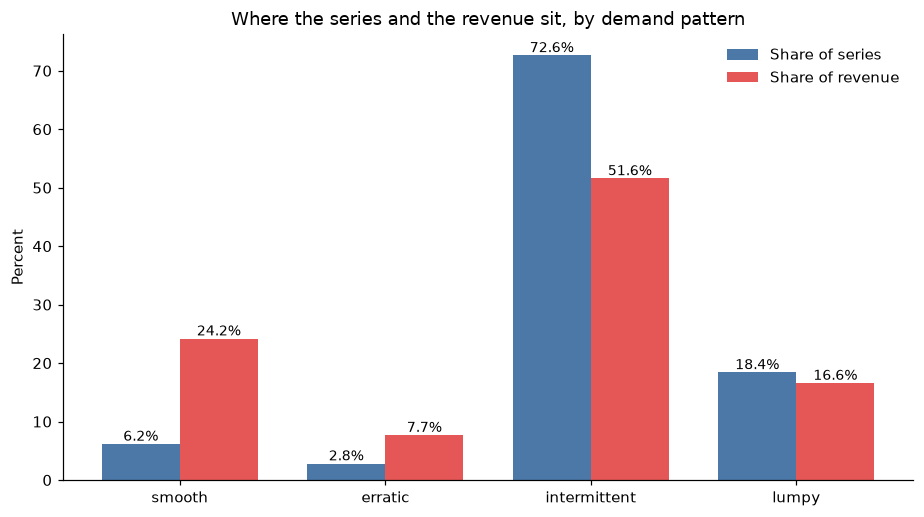

              series  revenue
demand_class                 
smooth           6.2     24.2
erratic          2.8      7.7
intermittent    72.6     51.6
lumpy           18.4     16.6


In [5]:
order = ["smooth", "erratic", "intermittent", "lumpy"]
g = cls.groupby("demand_class").agg(series=("item_id", "size"), revenue=("revenue", "sum")).reindex(order)
pct = g / g.sum() * 100

x = np.arange(len(order))
w = 0.38
fig, ax = plt.subplots(figsize=(8.5, 4.8))
b1 = ax.bar(x - w / 2, pct["series"], w, label="Share of series", color="#4c78a8")
b2 = ax.bar(x + w / 2, pct["revenue"], w, label="Share of revenue", color="#e45756")
ax.bar_label(b1, fmt="%.1f%%", fontsize=9)
ax.bar_label(b2, fmt="%.1f%%", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(order)
ax.set_ylabel("Percent")
ax.set_title("Where the series and the revenue sit, by demand pattern")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / "fig_demand_class_revenue.png")
plt.show()

print(pct.round(1))

## Chart 4: Revenue concentration (ABC curve)

Question: how many series make up 80% and 95% of revenue?
What to look for: class A (first 80% of revenue) takes about a third of all series, so revenue is spread wide, not the classic 20% / 80% split.

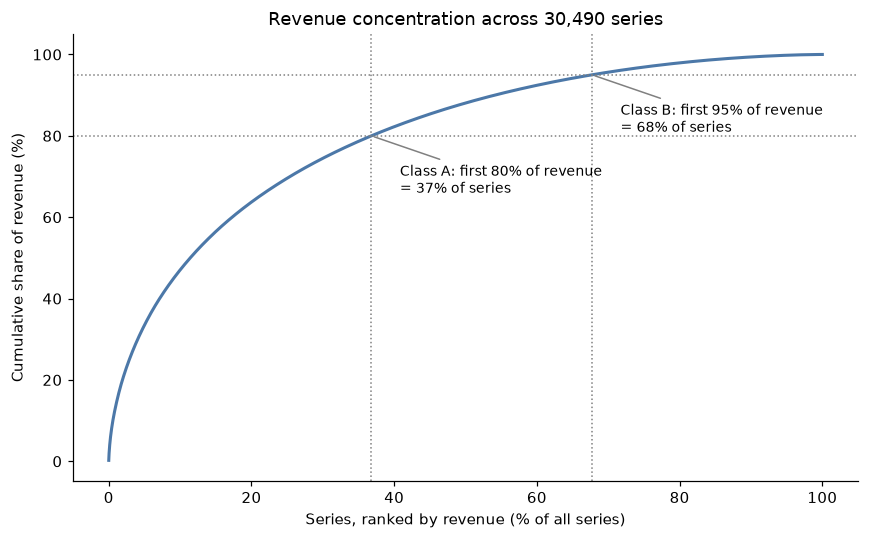

In [6]:
r = np.sort(cls["revenue"].to_numpy())[::-1]
cum = np.cumsum(r) / r.sum() * 100
frac = np.arange(1, len(r) + 1) / len(r) * 100

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(frac, cum, color="#4c78a8", lw=2)
for share, name in [(80, "A"), (95, "B")]:
    k = int(np.searchsorted(cum, share))
    ax.axhline(share, color="grey", ls=":", lw=1)
    ax.axvline(frac[k], color="grey", ls=":", lw=1)
    ax.annotate(f"Class {name}: first {share}% of revenue\n= {frac[k]:.0f}% of series",
                xy=(frac[k], share), xytext=(frac[k] + 4, share - 14), fontsize=9,
                arrowprops=dict(arrowstyle="-", color="grey"))
ax.set_xlabel("Series, ranked by revenue (% of all series)")
ax.set_ylabel("Cumulative share of revenue (%)")
ax.set_title("Revenue concentration across 30,490 series")
fig.tight_layout()
fig.savefig(FIG / "fig_abc_pareto.png")
plt.show()

## Chart 5: Service against stock held, backtest

Question: for the same service, how much stock does each policy hold?
One panel per order rule, all classes, last 224 days. Further up and left is better.
Blue = our policy, red = baseline (reorder at N days of average sales).

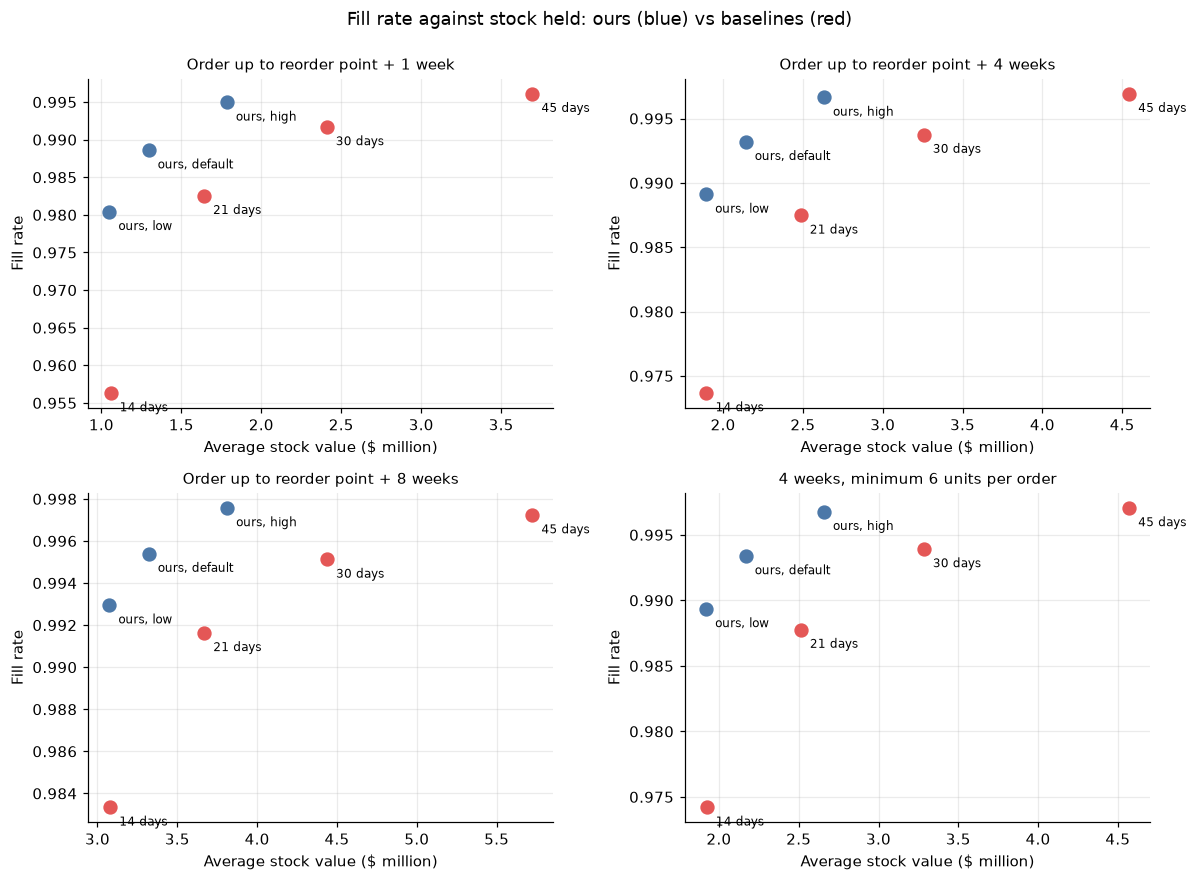

In [7]:
tr = pd.read_parquet(config.PROCESSED_DIR / "app_tradeoff.parquet")
g = tr.groupby(["rule", "scenario"], as_index=False)[["demand", "sold", "inv_value"]].sum()
g["fill"] = g["sold"] / g["demand"]
g["stock_m"] = g["inv_value"] / config.TEST_DAYS / 1e6

titles = {
    "current": "Order up to reorder point + 1 week",
    "batch4": "Order up to reorder point + 4 weeks",
    "batch8": "Order up to reorder point + 8 weeks",
    "batch4_moq6": "4 weeks, minimum 6 units per order",
}

def short(name):
    if name.startswith("ours_"):
        return "ours, " + name.split("_")[1]
    return name.replace("base_", "") .replace("d", " days")

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, rule in zip(axes.ravel(), titles):
    d = g[g["rule"] == rule]
    for _, row in d.iterrows():
        ours = row["scenario"].startswith("ours")
        ax.scatter(row["stock_m"], row["fill"], s=70, color="#4c78a8" if ours else "#e45756", zorder=3)
        ax.annotate(short(row["scenario"]), (row["stock_m"], row["fill"]),
                    textcoords="offset points", xytext=(6, -12), fontsize=8)
    ax.set_title(titles[rule], fontsize=10)
    ax.set_xlabel("Average stock value ($ million)")
    ax.set_ylabel("Fill rate")
    ax.grid(alpha=0.25)
fig.suptitle("Fill rate against stock held: ours (blue) vs baselines (red)", y=0.995)
fig.tight_layout()
fig.savefig(FIG / "fig_policy_tradeoff.png")
plt.show()

## Saved figures

In [8]:
for f in sorted(FIG.glob("fig_*.png")):
    print(f.name)

fig_abc_pareto.png
fig_assortment_growth.png
fig_demand_class_revenue.png
fig_policy_tradeoff.png
fig_zero_share_spread.png
